# 04 - Model error analysis
An overall score hides where a model fails. We slice the error by segment, check bias and residual autocorrelation, and measure what the 'event lead' features actually changed.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160
from src.config import connect, SCHEMA
con = connect(read_only=True)

In [2]:
from src.evaluation.error_analysis import load_enriched, segment_table, category_x_holiday, residual_autocorrelation, holiday_uplift
df = load_enriched(con)
len(df)

1019200

## Error by segment - final model (LightGBM)

In [3]:
segment_table(df, 'lightgbm')

,segment,wape,bias,share_of_rows,share_of_abs_error
0,Category: FOODS,0.625,-0.006,0.429,0.556
1,Category: HOBBIES,0.853,-0.009,0.286,0.183
2,Category: HOUSEHOLD,0.700,-0.008,0.286,0.260
3,Holiday weeks,0.663,-0.027,0.173,0.189
4,Non-holiday weeks,0.680,-0.002,0.827,0.811
5,Slow movers (<1 unit/day),1.212,0.033,0.305,0.117
6,Fast movers (>=1 unit/day),0.640,-0.010,0.695,0.883
7,Price promotion days,0.612,-0.017,0.078,0.108
8,SNAP days,0.668,-0.002,0.330,0.346


## Same slices for the baseline (28-day moving average)

In [4]:
segment_table(df, 'moving_avg_28')

,segment,wape,bias,share_of_rows,share_of_abs_error
0,Category: FOODS,0.658,-0.001,0.429,0.562
1,Category: HOBBIES,0.873,-0.002,0.286,0.180
2,Category: HOUSEHOLD,0.722,-0.000,0.286,0.258
3,Holiday weeks,0.698,-0.105,0.173,0.191
4,Non-holiday weeks,0.707,0.024,0.827,0.809
5,Slow movers (<1 unit/day),1.216,0.005,0.305,0.113
6,Fast movers (>=1 unit/day),0.670,-0.001,0.695,0.887
7,Price promotion days,0.634,-0.341,0.078,0.108
8,SNAP days,0.683,-0.062,0.330,0.340


## Category x holiday-week contribution to total error

In [5]:
category_x_holiday(df, 'lightgbm')[['category','holiday_week','wape','bias','share_of_total_error']]

,category,holiday_week,wape,bias,share_of_total_error
0,FOODS,False,0.629,0.002,0.446
1,FOODS,True,0.611,-0.036,0.111
2,HOBBIES,False,0.855,-0.010,0.152
3,HOBBIES,True,0.843,-0.006,0.032
4,HOUSEHOLD,False,0.698,-0.007,0.213
5,HOUSEHOLD,True,0.707,-0.014,0.047


## Residual autocorrelation (daily total residual, averaged over folds)
Values near zero at lag 7 mean the weekly pattern is captured.

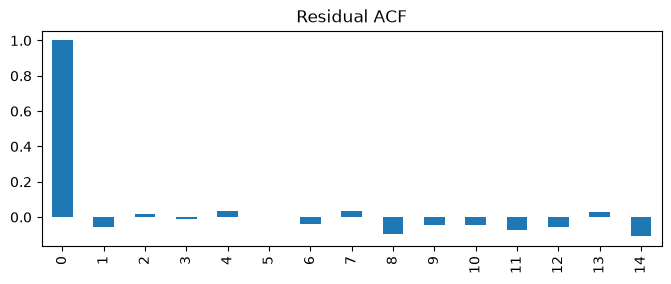

lag-7 autocorrelation: 0.034 | 95% noise band ~ +/- 0.37


In [6]:
acf = residual_autocorrelation(df, 'lightgbm')
acf.plot.bar(figsize=(8,2.8), title='Residual ACF'); plt.show()
print('lag-7 autocorrelation:', round(acf[7], 3), '| 95% noise band ~ +/-', round(1.96/np.sqrt(28),3))

## Action taken: event-lead features
`lightgbm_base` has no days-to-event/days-since-event features; `lightgbm` does.

In [7]:
print(holiday_uplift(df, 'lightgbm_base', 'lightgbm'))
rows = []
for m in ['seasonal_naive','lightgbm_base','lightgbm']:
    t = segment_table(df, m).set_index('segment').loc[['Holiday weeks','Non-holiday weeks']]
    rows.append(t[['wape','bias']].add_prefix(m+'_'))
pd.concat(rows, axis=1)

{'lightgbm_base': np.float64(0.6588252244578378), 'lightgbm': np.float64(0.6634759024342111)}


,seasonal_naive_wape,seasonal_naive_bias,lightgbm_base_wape,lightgbm_base_bias,lightgbm_wape,lightgbm_bias
segment,,,,,,
Holiday weeks,0.884,-0.125,0.659,-0.062,0.663,-0.027
Non-holiday weeks,0.942,0.045,0.682,0.007,0.680,-0.002


**Reading this:** the event features cut holiday-week *bias* (systematic under-forecasting) but left holiday-week WAPE roughly flat - the base model already sees `is_holiday`, `month`, `day_of_month` and `lag_364`, which proxy fixed-date events. The remaining error is mostly irreducible count noise.